**Estudiante**: Andres Felipe Ramirez Montaña
<br>
**Universidad Nacional de Colombia**

---
#FASE 1: Comprensión del Negocio
## *Business Understanding*

## CASO DE ESTUDIO

Para este proyecto se utilizara un dataset de un servicio de dinero movil operado en un pais africano. Este tipo de servicio permite a los usuarios manejar dinero desde su celular sin necesidad de un banco tradicional. Es algo clave en regiones donde el acceso bancario es limitado.

El crecimiento del mobile money trajo consigo un aumento del fraude financiero, segun el paper, el crecimiento uso del dinero movil ha incrementado las posibilidades de que criminales realicen activiades fraudulentas para eludir las medidas de seguridad.

<br>

**Objetivo de negocio:**
- Desarrollar mejores métodos de detección de fraude en transacciones de dinero móvil.

<br>

Pero para recolectar estos datos hubieron algunos obstaculos como:

<br>

**Falta de datos:**
- La mayoría de estos datos están protegidos por las empresas financieras, lo que dificulta la existencia de conjuntos de datos públicos disponibles.

<br>

**Solución:**
- Ante la falta de datos reales, se construye PySim, un simulador que genera datos sintéticos estadísticamente similares a los reales mediante **simulación basada en agentes** implementada en java con el framework **MASON**. Donde Cada "Client" (agente) tiene un perfil (límites de transacción, saldo máximo, edad, etc.) y decide qué transacción hacer en cada paso de tiempo, según distribuciones de probabilidad calculadas a partir del dataset real.
---

**Los 5 tipos de transacciones**

- **CASH-IN:** depositar efectivo en la cuenta a través de un merchant
- **CASH-OUT:** retirar efectivo desde un merchant
- **DEBIT:** enviar dinero del servicio móvil a una cuenta bancaria
- **PAYMENT:** pagar bienes/servicios a un merchant
- **TRANSFER:** enviar dinero a otro usuario del servicio


#FASE 2: Comprensión de los Datos
## *Data Understanding*

---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

In [ ]:
# Cargar el dataset
df = pd.read_csv("/content/drive/MyDrive/Elementos de Machine Learning/Projects/datasets/AIML Dataset.csv")

In [ ]:
print(f"Dataset shape: {df.shape[0]} filas x {df.shape[1]} columnas")
print("INFORMACION GENERAL","\n")
df.info()

Dataset shape: 6362620 filas x 11 columnas
INFORMACION GENERAL 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [ ]:
# Estadisticas descriptivas
print('\n ESTADÍSTICAS DESCRIPTIVAS — Variables numéricas:')
df.describe()


 ESTADÍSTICAS DESCRIPTIVAS — Variables numéricas:


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [ ]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [ ]:
df["isFraud"].value_counts()

,count
isFraud,
0,6354407
1,8213


In [ ]:
df['isFlaggedFraud'].value_counts()

,count
isFlaggedFraud,
0,6362604
1,16


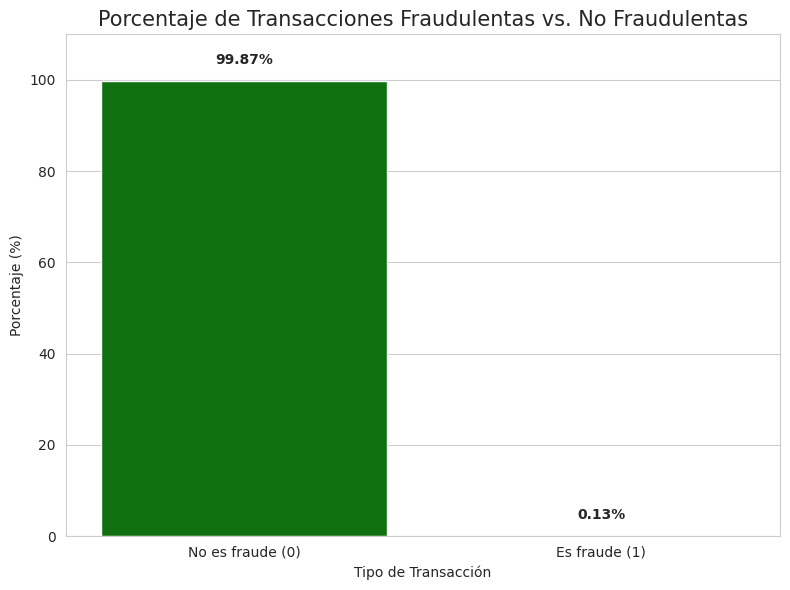

In [ ]:
fraud_counts = df['isFraud'].value_counts()
total_transactions = fraud_counts.sum()

# Calcular porcentajes
f_labels = ['No es fraude (0)', 'Es fraude (1)']
percentages = (fraud_counts / total_transactions * 100).round(2)

plt.figure(figsize=(8, 6))
ax = sns.barplot(x=f_labels, y=percentages, palette=['green', 'red'])

plt.title('Porcentaje de Transacciones Fraudulentas vs. No Fraudulentas', fontsize=15)
plt.xlabel('Tipo de Transacción')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 110)

# Añadir las etiquetas de porcentaje en las barras
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 15), # Increased vertical offset for the text
                textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

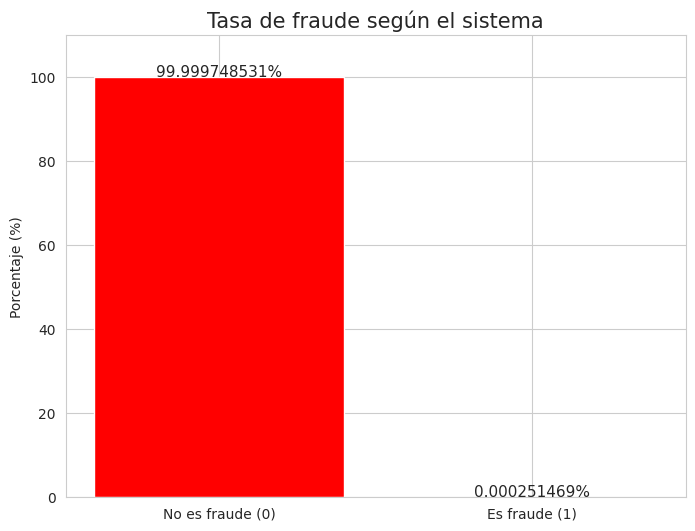

In [ ]:
# Estadística para 'isFlaggedFraud'
rate_fraud_flagged = df["isFlaggedFraud"].value_counts().sort_index()
porcentajes = (rate_fraud_flagged / rate_fraud_flagged.sum()) * 100
labels = ["No es fraude (0)", "Es fraude (1)"]

# Gráfica
plt.figure(figsize=(8,6))
bars = plt.bar(labels, porcentajes, color=["red", "green"])
for bar in bars:
    altura = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        altura + 0.2,
        f"{altura:.9f}%",
        ha="center",
        fontsize=11
    )

plt.ylabel("Porcentaje (%)")
plt.title("Tasa de fraude según el sistema", fontsize=15)
plt.ylim(0, 110)  # deja espacio para el texto
plt.show()

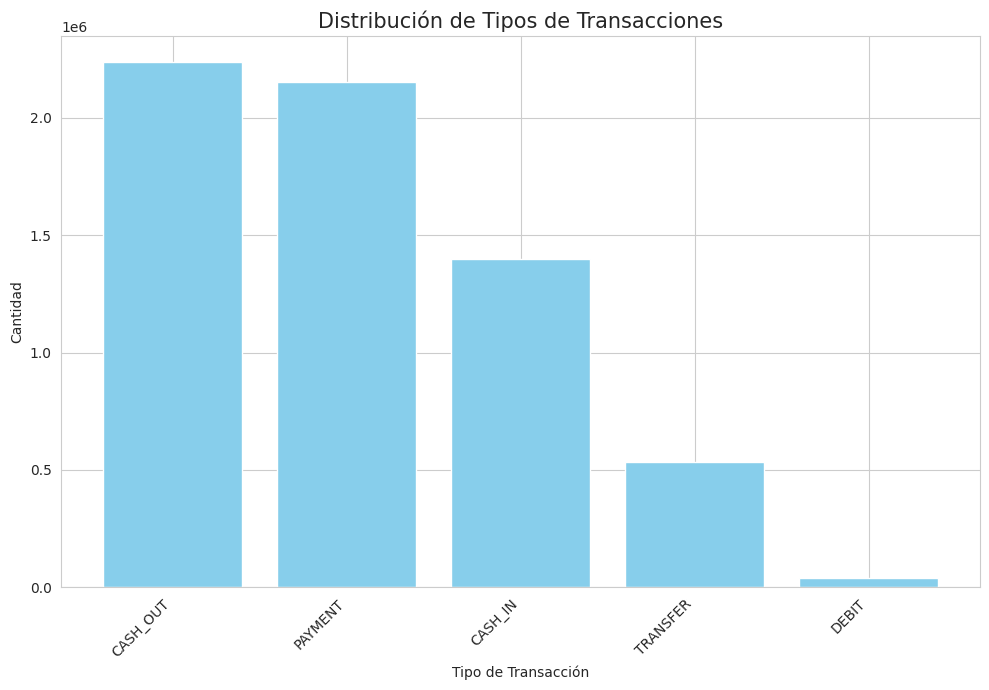

In [ ]:
# Revision de los tipos de transacciones
types = df['type'].value_counts()
plt.figure(figsize=(10, 7))
plt.bar(
    x=types.index,
    height=types.values,
    color='skyblue',
)

plt.title('Distribución de Tipos de Transacciones', fontsize=15)
plt.xlabel('Tipo de Transacción')
plt.ylabel('Cantidad')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

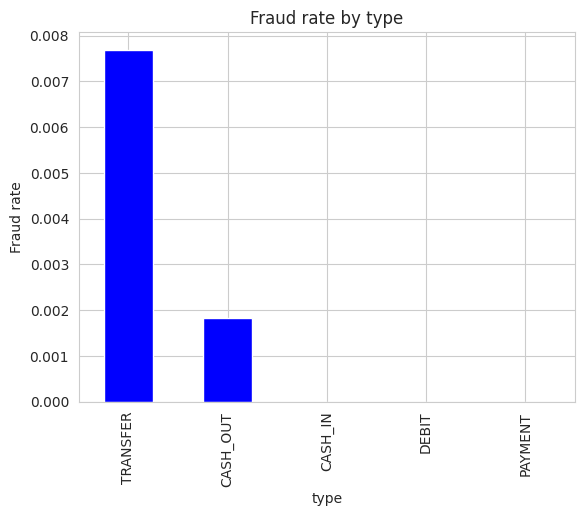

In [ ]:
fraud_by_type = df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_by_type.plot(kind="bar", title="Fraud rate by type", color="blue")
plt.ylabel("Fraud rate")
plt.show()

<p>Dado que la tasa de fraude es de $0.13$% entonce los tipos responsables de fraudes son las transferencias junto con los retiros de dinero en el sistema monetario, los otros tipos se pueden ver a continuación: <p>

In [ ]:
fraud_by_type

,isFraud
type,
TRANSFER,0.007688
CASH_OUT,0.001840
CASH_IN,0.000000
DEBIT,0.000000
PAYMENT,0.000000


In [ ]:
# Estadistica de la cantidad
df['amount'].describe().astype(int)

,amount
count,6362620
mean,179861
std,603858
min,0
25%,13389
50%,74871
75%,208721
max,92445516


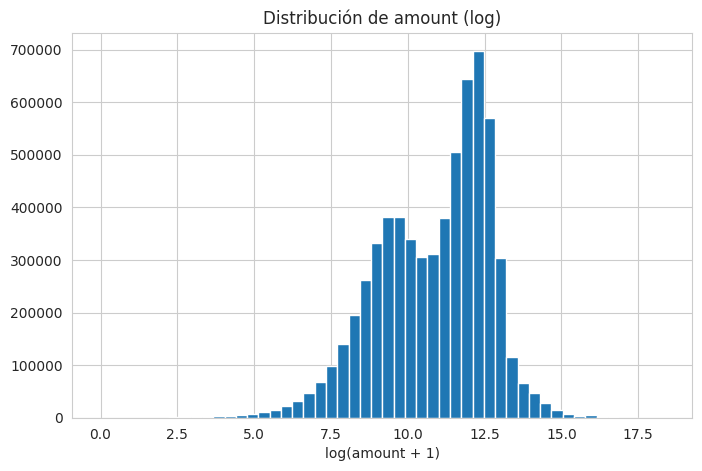

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(np.log1p(df["amount"]), bins=50)
plt.title("Distribución de amount (log)")
plt.xlabel("log(amount + 1)")
plt.show()

<p>Como se puede ver en la grafica anterior, hacia la derecha están las transacciones de mayor monto, por ejemplo:

- La barra llega a casi 700 000, significa que hay aproximadamente 700 mil transacciones con montos similares.
<p>


Es decir, la mayoría del dinero movido en el dataset no corresponde ni a montos muy pequeños ni a montos extremadamente grandes. Todo se concentran en valores entre 11 y 13 en unidades monetarias.

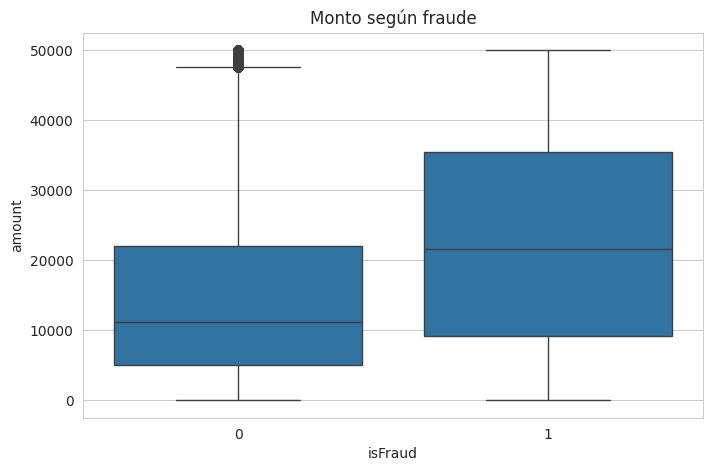

Valores atipicos
la cantidad de valores atipicos para amount es 338078 que corresponde a un 5.31% de los datos totales.


In [ ]:
# Relacion entre el fraude y el monto.
plt.figure(figsize=(8,5))
sns.boxplot(data=df[df['amount'] < 50_000], x="isFraud", y="amount")
plt.title("Monto según fraude")
plt.show()

print("="*60)
print("Valores atipicos")
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_sup= Q3 + 1.5 * IQR  # superior

# Contar la cantidad de valores atípicos
condicion = (df['amount'] < limite_inferior) | (
    df['amount'] > limite_sup
)

cantidad_outliers = condicion.sum()
print(f"la cantidad de valores atipicos para amount es {cantidad_outliers} que corresponde a un { round(cantidad_outliers / df.shape[0] * 100, 2) }% de los datos totales.")

<p>
Para $isFraud = 0$

Se observa que:

- La mediana está alrededor de 11 000.
- El 50% de las transacciones están aproximadamente entre 5 000 y 22 000.
- Existen algunos valores atípicos cerca de 48 000–50 000.


Para $isFraud = 1$

Se observa que:

- La mediana está alrededor de 21 000.
- El 50% de las transacciones están aproximadamente entre 9 000 y 35 000.
- En este rango $(< 50 000)$ prácticamente no aparecen outliers.



**Mini conclusión:** Como se puede ver en la grafica las transacciones fraudulentas tienden a tener montos mayores a los no fraudulentas, incluso en un rango menor $(<50.000)$

<p>

In [ ]:
df['amount'].describe().astype(int)

,amount
count,6362620
mean,179861
std,603858
min,0
25%,13389
50%,74871
75%,208721
max,92445516


In [ ]:
cuartiles = (
    df.groupby("isFraud")["amount"]
      .quantile([0.25, 0.50, 0.75])
      .unstack()
)

cuartiles.columns = ["Q1", "Q2 (Mediana)", "Q3"]

print(cuartiles, "\n")

# Primer cuartil
print(f"Transacciones fraudulentas (isFraud = 1):")
print(f"  - El 25% de las transacciones tienen un monto entre 0 y {cuartiles.loc[1, 'Q1']:.2f}")

print(f"\nTransacciones no fraudulentas (isFraud = 0):")
print(f"  - El 25% de las transacciones tienen un monto entre 0 y {cuartiles.loc[0, 'Q1']:.2f}")

# Segundo cuartil
print("\nSegundo cuartil (Q2 - Mediana)")
print(f"  - El siguiente 25% de las transacciones fraudulentas tienen montos entre "
      f"{cuartiles.loc[1, 'Q1']:.2f} y {cuartiles.loc[1, 'Q2 (Mediana)']:.2f}")

print(f"  - El siguiente 25% de las transacciones no fraudulentas tienen montos entre "
      f"{cuartiles.loc[0, 'Q1']:.2f} y {cuartiles.loc[0, 'Q2 (Mediana)']:.2f}")

# Tercer cuartil
print("\nTercer cuartil (Q3)")
print(f"  - El siguiente 25% de las transacciones fraudulentas tienen montos entre "
      f"{cuartiles.loc[1, 'Q2 (Mediana)']:.2f} y {cuartiles.loc[1, 'Q3']:.2f}")

print(f"  - El siguiente 25% de las transacciones no fraudulentas tienen montos entre "
      f"{cuartiles.loc[0, 'Q2 (Mediana)']:.2f} y {cuartiles.loc[0, 'Q3']:.2f}")

# Último cuartil
print("\nÚltimo 25%")
print(f"  - El 25% restante de las transacciones fraudulentas tienen montos superiores a {cuartiles.loc[1, 'Q3']:.2f}")

print(f"  - El 25% restante de las transacciones no fraudulentas tienen montos superiores a {cuartiles.loc[0, 'Q3']:.2f}")

                 Q1  Q2 (Mediana)          Q3
isFraud                                      
0         13368.395      74684.72   208364.76
1        127091.330     441423.44  1517771.48 

Transacciones fraudulentas (isFraud = 1):
  - El 25% de las transacciones tienen un monto entre 0 y 127091.33

Transacciones no fraudulentas (isFraud = 0):
  - El 25% de las transacciones tienen un monto entre 0 y 13368.40

Segundo cuartil (Q2 - Mediana)
  - El siguiente 25% de las transacciones fraudulentas tienen montos entre 127091.33 y 441423.44
  - El siguiente 25% de las transacciones no fraudulentas tienen montos entre 13368.40 y 74684.72

Tercer cuartil (Q3)
  - El siguiente 25% de las transacciones fraudulentas tienen montos entre 441423.44 y 1517771.48
  - El siguiente 25% de las transacciones no fraudulentas tienen montos entre 74684.72 y 208364.76

Último 25%
  - El 25% restante de las transacciones fraudulentas tienen montos superiores a 1517771.48
  - El 25% restante de las transacciones n

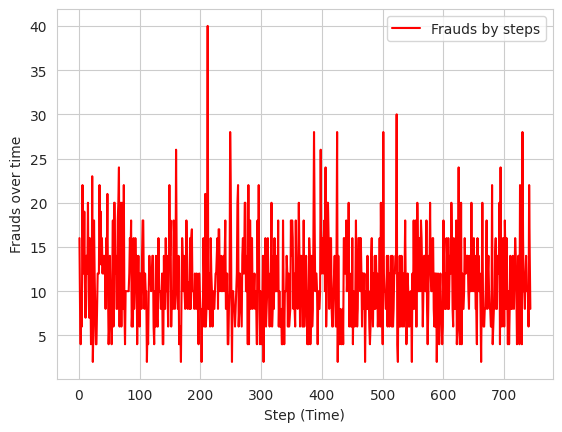

In [ ]:
# Revisar algunas correlaciones con otras variables:

# Step
frauds_by_step = df[df['isFraud'] == 1]["step"].value_counts().sort_index()
plt.plot(frauds_by_step.index, frauds_by_step.values, color='red', label="Frauds by steps")
plt.xlabel("Step (Time)")
plt.ylabel("Frauds over time")
plt.grid(True)
plt.legend()
plt.show()

<p>No muestra ninguna relacion, por ende podemos eliminar esa columna.<p>

In [ ]:
# Eliminación de la columna
df.drop(columns=["step"], inplace=True)
df

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.00,0.00,0,0
1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.00,0.00,0,0
2,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0
4,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.00,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...
6362615,CASH_OUT,339682.13,C786484425,339682.13,0.00,C776919290,0.00,339682.13,1,0
6362616,TRANSFER,6311409.28,C1529008245,6311409.28,0.00,C1881841831,0.00,0.00,1,0
6362617,CASH_OUT,6311409.28,C1162922333,6311409.28,0.00,C1365125890,68488.84,6379898.11,1,0
6362618,TRANSFER,850002.52,C1685995037,850002.52,0.00,C2080388513,0.00,0.00,1,0


In [ ]:
# Revisión de usuarios
top_senders = df["nameOrig"].value_counts().head(20)
top_senders

,count
nameOrig,
C1530544995,3
C545315117,3
C724452879,3
C1784010646,3
C1677795071,3
C1462946854,3
C1065307291,3
C1999539787,3
C2098525306,3


In [ ]:
top_receivers = df["nameDest"].value_counts().head(20).sort_values(ascending=False)
top_receivers

,count
nameDest,
C1286084959,113
C985934102,109
C665576141,105
C2083562754,102
C248609774,101
C1590550415,101
C1789550256,99
C451111351,99
C1360767589,98


In [ ]:
# Analisis del fraude por parte de los emisores de transacciones
frauds_users = df[df['isFraud'] == 1]["nameOrig"].value_counts()

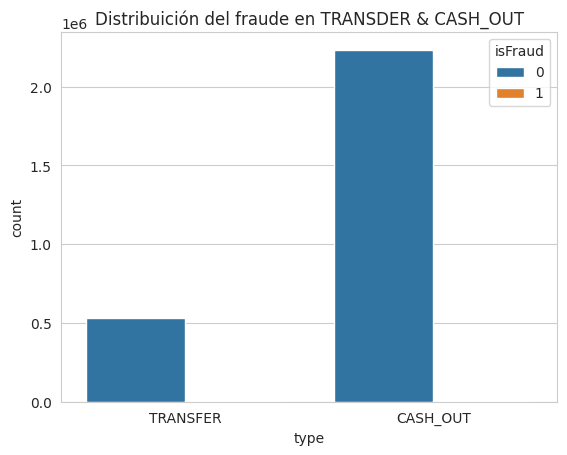

Transacciones fraudulentas:
type
CASH_OUT    4116
TRANSFER    4097
dtype: int64

Transacciones no fraudulentas:
type
CASH_OUT    2233384
TRANSFER     528812
dtype: int64


In [ ]:
fraud_types = df[df["type"].isin(["CASH_OUT", "TRANSFER"])]
fraud_types["type"].value_counts()
sns.countplot(data=fraud_types, x="type", hue="isFraud")
plt.title("Distribuición del fraude en TRANSDER & CASH_OUT")
plt.show()

print("=" * 60)

isFraud = (
    fraud_types[fraud_types["isFraud"] == 1]
    .groupby("type")
    .size()
)

noFraud = (
    fraud_types[fraud_types["isFraud"] == 0]
    .groupby("type")
    .size()
)

print("Transacciones fraudulentas:")
print(isFraud)

print("\nTransacciones no fraudulentas:")
print(noFraud)

In [ ]:
df.columns

Index(['type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

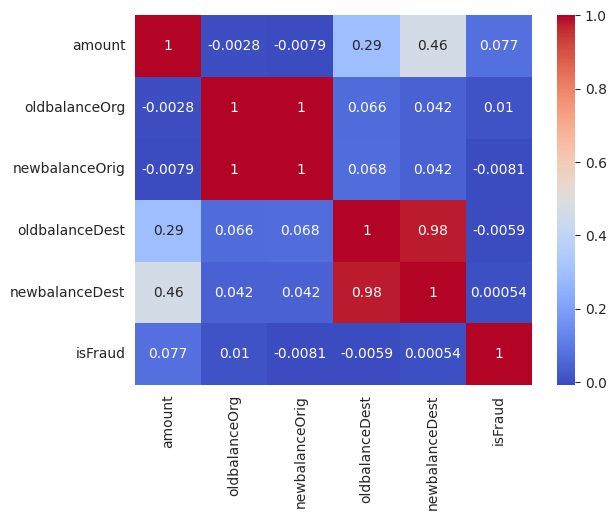

In [ ]:
# Matriz de correlacion

corr = df[["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

#FASE 3: Preparación de los Datos
## *Data Preparation*


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score,confusion_matrix, classification_report, f1_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [ ]:
df_model = df.drop(['nameOrig', 'nameDest', 'isFlaggedFraud'], axis=1)
print(df_model.head(10))
print(df_model.shape)

       type    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0   PAYMENT   9839.64      170136.00       160296.36             0.0   
1   PAYMENT   1864.28       21249.00        19384.72             0.0   
2  TRANSFER    181.00         181.00            0.00             0.0   
3  CASH_OUT    181.00         181.00            0.00         21182.0   
4   PAYMENT  11668.14       41554.00        29885.86             0.0   
5   PAYMENT   7817.71       53860.00        46042.29             0.0   
6   PAYMENT   7107.77      183195.00       176087.23             0.0   
7   PAYMENT   7861.64      176087.23       168225.59             0.0   
8   PAYMENT   4024.36        2671.00            0.00             0.0   
9     DEBIT   5337.77       41720.00        36382.23         41898.0   

   newbalanceDest  isFraud  
0            0.00        0  
1            0.00        0  
2            0.00        1  
3            0.00        1  
4            0.00        0  
5            0.00        0  
6   

In [ ]:
categorical = ["type"]
numeric = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]

In [ ]:
y = df_model["isFraud"]
X = df_model.drop(["isFraud"], axis=1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42) # 70% para entrenar y 30% para test

print(f"X train = {X_train.shape}")
print(f"X test = {X_test.shape}")
print(f"y train = {y_train.shape}")
print(f"y test = {y_test.shape}")

X train = (4453834, 6)
X test = (1908786, 6)
y train = (4453834,)
y test = (1908786,)


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
    ]
)

#FASE 4: Modelado
## *Modeling*


In [ ]:
RANDOM_STATE = 42

In [ ]:
pipeline_lr = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(
        class_weight="balanced",
        max_iter=1_000,
        random_state=RANDOM_STATE
    ))
])

pipeline_rf = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

#FASE 5: Evaluación
## *Evaluation*

Entrenando Logistic Regression...

Modelo: Logistic Regression
Accuracy : 0.9454
Precision: 0.0213
Recall   : 0.9306
F1 Score : 0.0417

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1906351
           1       0.02      0.93      0.04      2435

    accuracy                           0.95   1908786
   macro avg       0.51      0.94      0.51   1908786
weighted avg       1.00      0.95      0.97   1908786



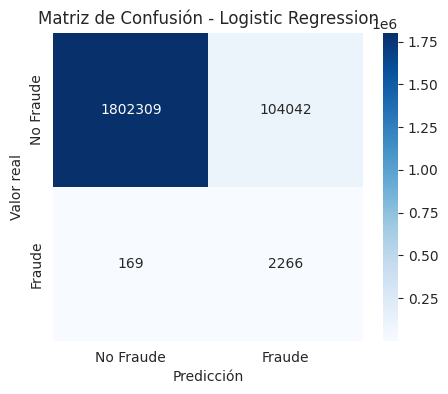

Entrenando Random Forest...

Modelo: Random Forest
Accuracy : 0.9997
Precision: 0.9571
Recall   : 0.7795
F1 Score : 0.8592

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906351
           1       0.96      0.78      0.86      2435

    accuracy                           1.00   1908786
   macro avg       0.98      0.89      0.93   1908786
weighted avg       1.00      1.00      1.00   1908786



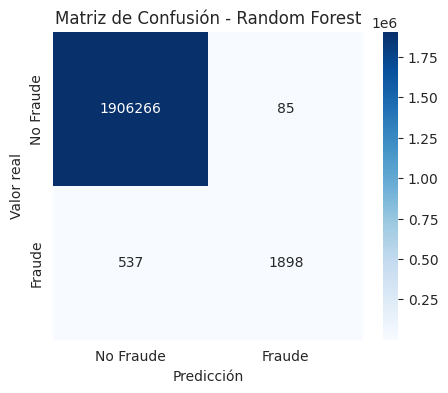


Resumen de resultados


,Modelo,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.945405,0.021315,0.930595,0.041676
1,Random Forest,0.999674,0.957136,0.779466,0.859212


In [ ]:
models = {
    "Logistic Regression": pipeline_lr,
    "Random Forest": pipeline_rf
}
results = []

for model_name, model in models.items():
  print("=" * 80)
  print(f"Entrenando {model_name}...")
  model.fit(X_train, y_train)

  y_pred = model.predict(X_test)
  y_prob = model.predict_proba(X_test)[:, 1]

  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)


  print(f"\nModelo: {model_name}")
  print(f"Accuracy : {acc:.4f}")
  print(f"Precision: {prec:.4f}")
  print(f"Recall   : {rec:.4f}")
  print(f"F1 Score : {f1:.4f}")

  print("\nClassification Report")
  print(classification_report(y_test, y_pred))

  cm = confusion_matrix(y_test, y_pred)
  plt.figure(figsize=(5,4))
  sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Fraude", "Fraude"],
        yticklabels=["No Fraude", "Fraude"]
    )
  plt.title(f"Matriz de Confusión - {model_name}")
  plt.xlabel("Predicción")
  plt.ylabel("Valor real")
  plt.show()
  results.append({
        "Modelo": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1    })


results_df = pd.DataFrame(results)

print("\nResumen de resultados")
display(results_df)

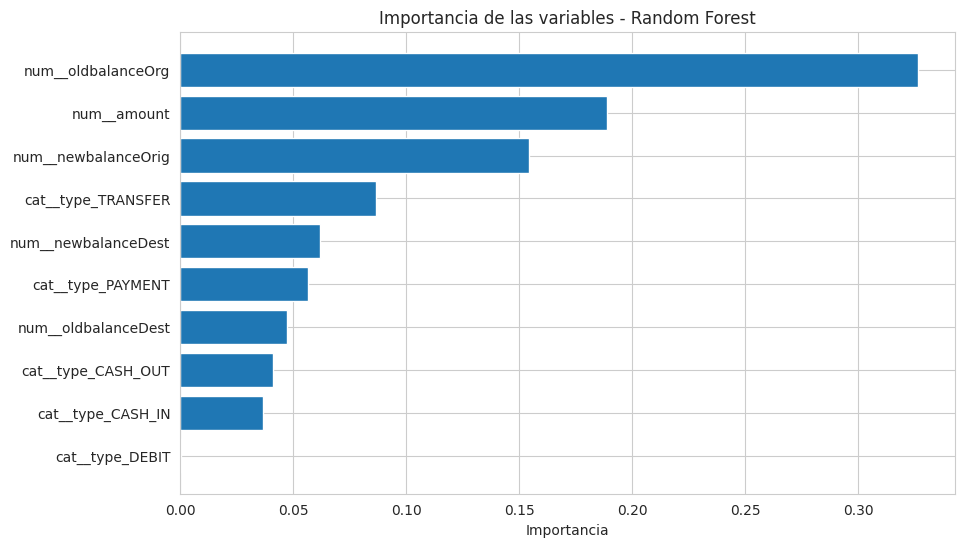

In [ ]:
# Obtener el preprocesador y el modelo
prep = pipeline_rf.named_steps["prep"]
rf = pipeline_rf.named_steps["clf"]

# Nombres de todas las variables después del preprocesamiento
feature_names = prep.get_feature_names_out()

# Importancias
importancias = rf.feature_importances_

# DataFrame
importance_df = pd.DataFrame({
    "Variable": feature_names,
    "Importancia": importancias
})

importance_df = importance_df.sort_values(
    by="Importancia",
    ascending=False
)

plt.figure(figsize=(10,6))

plt.barh(
    importance_df["Variable"],
    importance_df["Importancia"]
)

plt.gca().invert_yaxis()

plt.title("Importancia de las variables - Random Forest")
plt.xlabel("Importancia")
plt.show()

## Interpretación de las métricas

En un problema de detección de fraude no todas las métricas tienen la misma importancia, ya que el conjunto de datos está altamente desbalanceado (la mayoría de las transacciones son legítimas).

- **Accuracy (Exactitud):** Indica el porcentaje de predicciones correctas realizadas por el modelo. Sin embargo, en este tipo de problemas puede ser una métrica engañosa, ya que un modelo podría obtener una alta exactitud simplemente clasificando casi todas las transacciones como no fraudulentas.

- **Precision (Precisión):** Mide qué porcentaje de las transacciones que el modelo clasificó como fraudulentas realmente eran fraude. Una precisión alta significa que el modelo genera pocas falsas alarmas, lo que reduce la cantidad de transacciones legítimas que deben ser revisadas por un analista.

- **Recall (Sensibilidad):** Indica qué porcentaje de todos los fraudes reales fue detectado por el modelo. En detección de fraude esta métrica suele ser muy importante, ya que un bajo Recall implica que muchos fraudes pasan desapercibidos, generando pérdidas económicas.

- **F1-Score:** Es la media armónica entre la Precisión y el Recall. Esta métrica busca un equilibrio entre detectar la mayor cantidad de fraudes posibles y evitar generar demasiadas falsas alarmas, siendo especialmente útil en conjuntos de datos desbalanceados como el utilizado en este proyecto.

## Comparación de Modelos

Se entrenaron dos modelos de clasificación para la detección de fraude: **Regresión Logística** y **Random Forest**, utilizando un *Pipeline* para el preprocesamiento de los datos.

| Modelo | Accuracy | Precision | Recall | F1-Score |
|--------|---------:|----------:|--------:|---------:|
| Logistic Regression | 94.54% | 2.13% | **93.06%** | 4.17% |
| Random Forest | **99.97%** | **95.71%** | 77.95% | **85.92%** |

### Análisis

- **Regresión Logística**
  - Detectó la mayoría de los fraudes (Recall = 93.06%).
  - Sin embargo, presentó una precisión muy baja (2.13%), lo que significa que generó una gran cantidad de falsas alarmas al clasificar muchas transacciones legítimas como fraudulentas.

- **Random Forest**
  - Obtuvo una precisión muy alta (95.71%), indicando que la mayoría de las transacciones clasificadas como fraude realmente lo eran.
  - Aunque su Recall fue menor (77.95%), logró un excelente equilibrio entre precisión y capacidad de detección, reflejado en un **F1-Score de 85.92%**.

### Conclusión

En este problema de detección de fraude, **Random Forest** presentó el mejor desempeño general. Aunque identificó un porcentaje menor de fraudes que la Regresión Logística, redujo considerablemente los falsos positivos y alcanzó un equilibrio mucho más adecuado entre precisión y Recall, convirtiéndose en el modelo más apropiado para este conjunto de datos.

#FASE 6: Despliegue
## *Deployment*

In [ ]:
import joblib

joblib.dump(pipeline_lr, "LogisticR.joblib")
joblib.dump(pipeline_rf, "RandomF.joblib")

['RandomF.joblib']

# Referencias

- Dataset: [Kaggle Fraud Detection Dataset](https://www.kaggle.com/datasets/amanalisiddiqui/fraud-detection-dataset/data)

- (PDF) PAYSIM: A FINANCIAL MOBILE MONEY SIMULATOR FOR FRAUD DETECTION. (n.d.). ResearchGate. https://www.researchgate.net/publication/313138956_PAYSIM_A_FINANCIAL_MOBILE_MONEY_SIMULATOR_FOR_FRAUD_DETECTION